# Task 2 (Easy) – Exploratory Data Analysis (EDA): Netflix Dataset

**Goal:** Explore the Netflix dataset to uncover trends, patterns and insights.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

NETFLIX_RED, DARK = "#E50914", "#221F1F"
TYPE_COLORS = {"Movie": NETFLIX_RED, "TV Show": DARK}

df = pd.read_csv(r"D:\Ausify_internship_task\data\Dataset.csv", parse_dates=["date_added"])
print("Shape:", df.shape)
df.head()

Shape: (8786, 26)


,show_id,type,title,director,num_directors,director_missing,country,country_missing,genres,primary_genre,...,year_added,quarter_added,month_added,month_name,day_of_week,years_to_netflix,added_before_release,duration_minutes,movie_length_category,seasons
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,1,False,United States,False,Documentaries,Documentaries,...,2021,3,9,September,Saturday,1,False,90.0,Medium (60-90 min),NaN
1,s3,TV Show,Ganglands,Julien Leclercq,1,False,France,False,"Crime TV Shows, International TV Shows, TV Act...",Crime TV Shows,...,2021,3,9,September,Friday,0,False,NaN,NaN,1.0
2,s6,TV Show,Midnight Mass,Mike Flanagan,1,False,United States,False,"TV Dramas, TV Horror, TV Mysteries",TV Dramas,...,2021,3,9,September,Friday,0,False,NaN,NaN,1.0
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,1,False,Brazil,False,"Children & Family Movies, Comedies",Children & Family Movies,...,2021,3,9,September,Wednesday,0,False,91.0,Long (90-120 min),NaN
4,s8,Movie,Sankofa,Haile Gerima,1,False,United States,False,"Dramas, Independent Movies, International Movies",Dramas,...,2021,3,9,September,Friday,28,False,125.0,Very long (>120 min),NaN


## Step 1 – Analyze dataset structure and statistics

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8786 entries, 0 to 8785
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   show_id                8786 non-null   str           
 1   type                   8786 non-null   str           
 2   title                  8786 non-null   str           
 3   director               8786 non-null   str           
 4   num_directors          8786 non-null   int64         
 5   director_missing       8786 non-null   bool          
 6   country                8786 non-null   str           
 7   country_missing        8786 non-null   bool          
 8   genres                 8786 non-null   str           
 9   primary_genre          8786 non-null   str           
 10  num_genres             8786 non-null   int64         
 11  rating                 8786 non-null   str           
 12  rating_category        8786 non-null   str           
 13  release_year  

In [3]:
# Data dictionary: columns, types, unique values, nulls
pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notnull().sum(),
    "nulls": df.isnull().sum(),
    "unique": df.nunique(),
    "example": df.iloc[0].astype(str).str[:30],
})

,dtype,non_null,nulls,unique,example
show_id,str,8786,0,8786,s1
type,str,8786,0,2,Movie
title,str,8786,0,8786,Dick Johnson Is Dead
director,str,8786,0,4528,Kirsten Johnson
num_directors,int64,8786,0,13,1
director_missing,bool,8786,0,2,False
country,str,8786,0,86,United States
country_missing,bool,8786,0,2,False
genres,str,8786,0,513,Documentaries
primary_genre,str,8786,0,36,Documentaries


In [4]:
# Numeric summary
num_cols = ["release_year", "year_added", "years_to_netflix", "num_genres", "num_directors", "duration_minutes", "seasons"]
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
release_year,8786.0,2014.18,8.83,1925.0,2013.0,2017.0,2019.0,2021.0
year_added,8786.0,2018.87,1.57,2008.0,2018.0,2019.0,2020.0,2021.0
years_to_netflix,8786.0,4.69,8.79,-3.0,0.0,1.0,5.0,93.0
num_genres,8786.0,2.19,0.78,1.0,2.0,2.0,3.0,3.0
num_directors,8786.0,0.80,0.70,0.0,0.0,1.0,1.0,13.0
duration_minutes,6123.0,99.57,28.28,3.0,87.0,98.0,114.0,312.0
seasons,2663.0,1.75,1.55,1.0,1.0,1.0,2.0,17.0


In [5]:
# Categorical summary
cat_cols = ["type", "country", "rating", "rating_category", "primary_genre", "release_decade"]
df[cat_cols].describe().T

,count,unique,top,freq
type,8786,2,Movie,6123
country,8786,86,United States,3240
rating,8786,14,TV-MA,3204
rating_category,8786,5,Adults,4005
primary_genre,8786,36,Dramas,1597
release_decade,8786,10,2010s,5909


**Observations**
- 8,786 titles and 26 columns after cleaning; `duration_minutes` is only filled for movies and `seasons` only for TV shows (the nulls are expected, not errors).
- Titles were released between **1925 and 2021**, but the median release year is **2017** – the catalogue is dominated by recent content.
- The median title reached Netflix just **1 year** after release (`years_to_netflix`), and at least a quarter were added in their release year.

## Step 2 – Content distribution by type

In [6]:
type_counts = df["type"].value_counts()
type_pct = (type_counts / len(df) * 100).round(1)
pd.DataFrame({"count": type_counts, "percent": type_pct})

,count,percent
type,,
Movie,6123,69.7
TV Show,2663,30.3


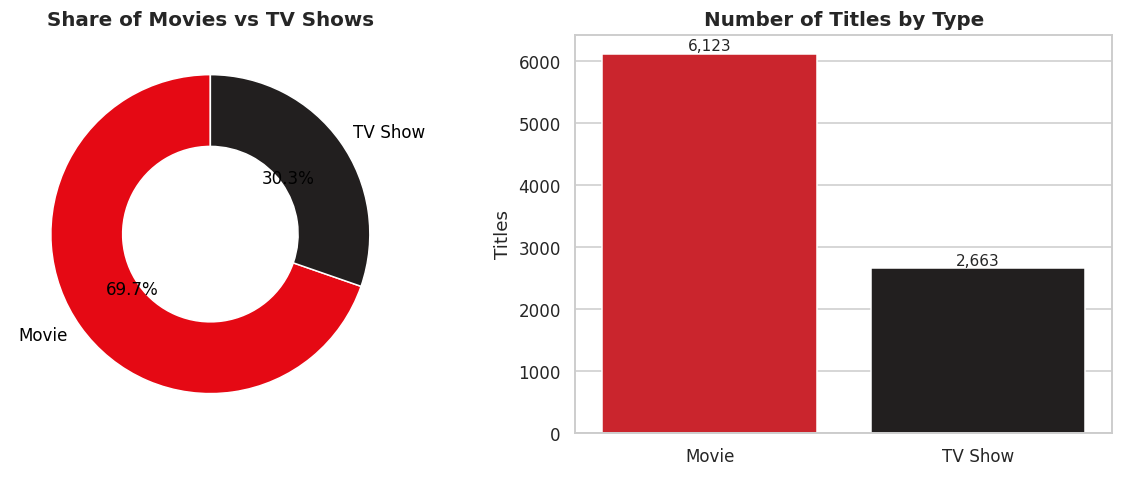

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Donut chart
axes[0].pie(type_counts, labels=type_counts.index, autopct="%1.1f%%", startangle=90,
            colors=[TYPE_COLORS[t] for t in type_counts.index],
            wedgeprops=dict(width=0.45, edgecolor="white"), textprops={"color": "black", "fontsize": 11})
axes[0].set_title("Share of Movies vs TV Shows")

# Count plot
sns.countplot(data=df, x="type", hue="type", palette=TYPE_COLORS, order=type_counts.index, ax=axes[1], legend=False)
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height()),
                     ha="center", va="bottom", fontsize=10)
axes[1].set_title("Number of Titles by Type"); axes[1].set_xlabel(""); axes[1].set_ylabel("Titles")
plt.tight_layout(); plt.show()

Movies make up roughly **70%** of the catalogue and TV shows about **30%** – more than twice as many movies as shows.

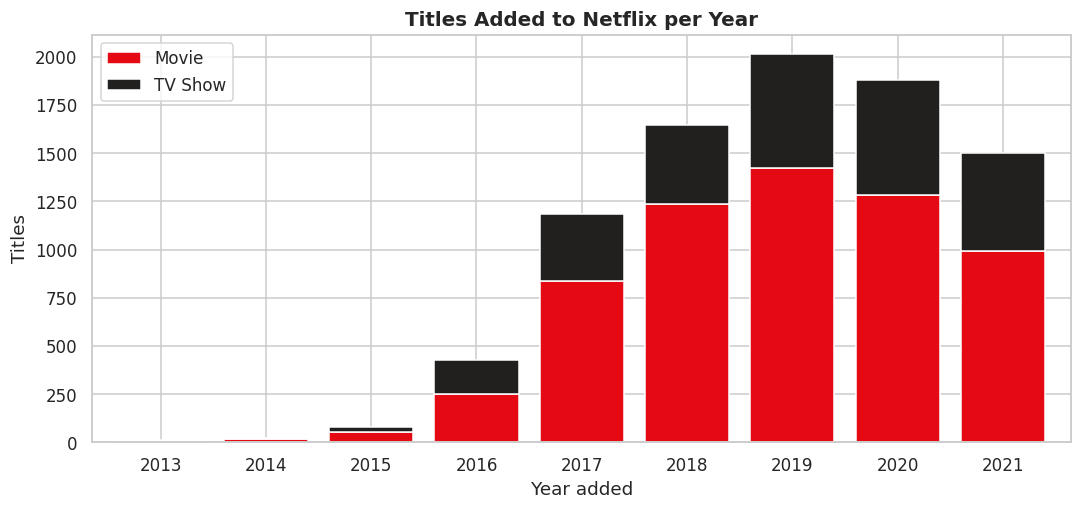

TV show share of additions (%):
year_added
2013    45.5
2014    20.8
2015    31.7
2016    41.1
2017    29.5
2018    25.0
2019    29.4
2020    31.7
2021    33.7


In [8]:
# How has the mix changed over time? (titles added per year)
added = df.groupby(["year_added", "type"]).size().unstack(fill_value=0)
added = added.loc[2013:]          # earlier years have only a handful of titles

ax = added.plot(kind="bar", stacked=True, figsize=(10, 4.8), color=[TYPE_COLORS[c] for c in added.columns], width=0.8)
ax.set_title("Titles Added to Netflix per Year"); ax.set_xlabel("Year added"); ax.set_ylabel("Titles")
plt.xticks(rotation=0); plt.legend(title="")
plt.tight_layout(); plt.show()

share = (added["TV Show"] / added.sum(axis=1) * 100).round(1)
print("TV show share of additions (%):")
print(share.to_string())

Additions grew explosively from 2016, **peaking in 2019** (about 2,000 titles), then eased in 2020–2021. TV shows' share of additions dipped to about 25% in 2018 and has since recovered to ~34% in 2021, suggesting a renewed tilt towards series.

## Step 3 – Top countries and categories

### 3.1 Top countries

In [9]:
known = df[df["country"] != "Unknown"]          # 'Unknown' is imputed, exclude it from country rankings
top_countries = known["country"].value_counts().head(10)
print(f"Distinct countries: {known['country'].nunique()}")
top_countries.to_frame("titles").assign(percent_of_all=lambda d: (d["titles"] / len(df) * 100).round(1))

Distinct countries: 85


,titles,percent_of_all
country,,
United States,3240,36.9
India,1056,12.0
United Kingdom,638,7.3
Pakistan,420,4.8
Canada,271,3.1
Japan,259,2.9
South Korea,214,2.4
France,213,2.4
Spain,182,2.1


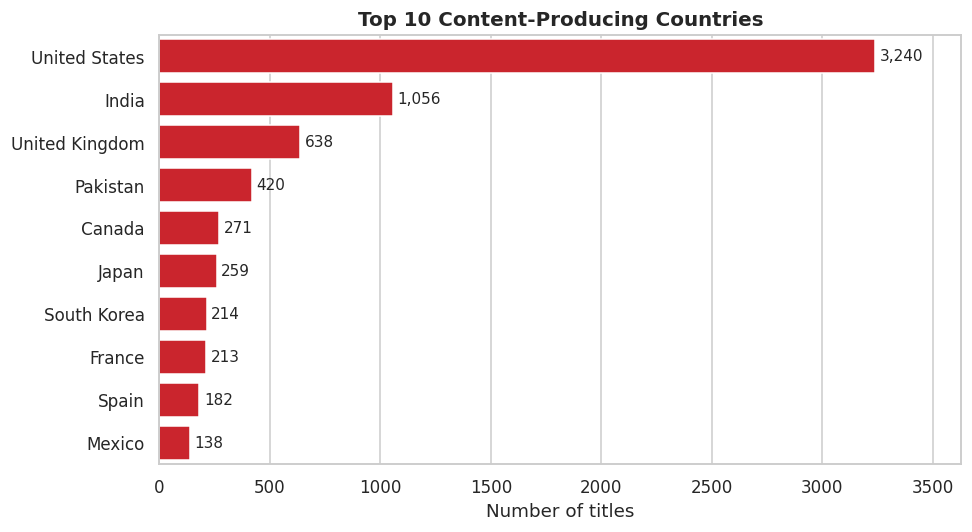

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=top_countries.values, y=top_countries.index, color=NETFLIX_RED, ax=ax)
for i, v in enumerate(top_countries.values):
    ax.text(v + 20, i, f"{v:,}", va="center", fontsize=10)
ax.set_title("Top 10 Content-Producing Countries"); ax.set_xlabel("Number of titles"); ax.set_ylabel("")
ax.set_xlim(0, top_countries.max() * 1.12)
plt.tight_layout(); plt.show()

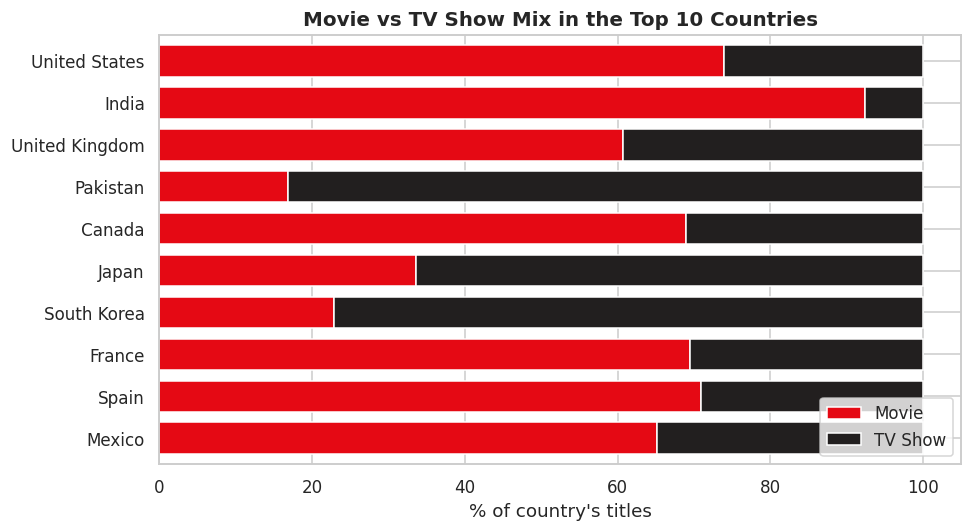

type,Movie,TV Show
country,,
United States,73.9,26.1
India,92.3,7.7
United Kingdom,60.7,39.3
Pakistan,16.9,83.1
Canada,69.0,31.0
Japan,33.6,66.4
South Korea,22.9,77.1
France,69.5,30.5
Spain,70.9,29.1


In [11]:
# Movie vs TV mix inside each of the top 10 countries
mix = (pd.crosstab(known["country"], known["type"], normalize="index") * 100).loc[top_countries.index]

ax = mix.plot(kind="barh", stacked=True, figsize=(9, 5), color=[TYPE_COLORS[c] for c in mix.columns], width=0.75)
ax.invert_yaxis(); ax.set_xlabel("% of country's titles"); ax.set_ylabel("")
ax.set_title("Movie vs TV Show Mix in the Top 10 Countries"); ax.legend(title="", loc="lower right")
plt.tight_layout(); plt.show()
mix.round(1)

- The **United States** leads with ~3,240 titles (about 37% of the catalogue), followed by **India** (~1,056) and the **United Kingdom** (~638).
- Country mix differs sharply: **South Korea (77%)** and **Japan (66%)** are TV-heavy (K-dramas and anime), while **India (92% movies)** is movie-heavy. Surprisingly, **Pakistan is 83% TV shows**.

### 3.2 Top categories (genres)

In [12]:
# 'genres' holds several comma-separated values -> explode so each genre is counted once per title
genres = df.assign(genre=df["genres"].str.split(", ")).explode("genre").reset_index(drop=True)

top_genres = genres["genre"].value_counts().head(12)
top_genres.to_frame("titles")

,titles
genre,
International Movies,2751
Dramas,2423
Comedies,1673
International TV Shows,1348
Documentaries,869
Action & Adventure,859
TV Dramas,761
Independent Movies,755
Children & Family Movies,641


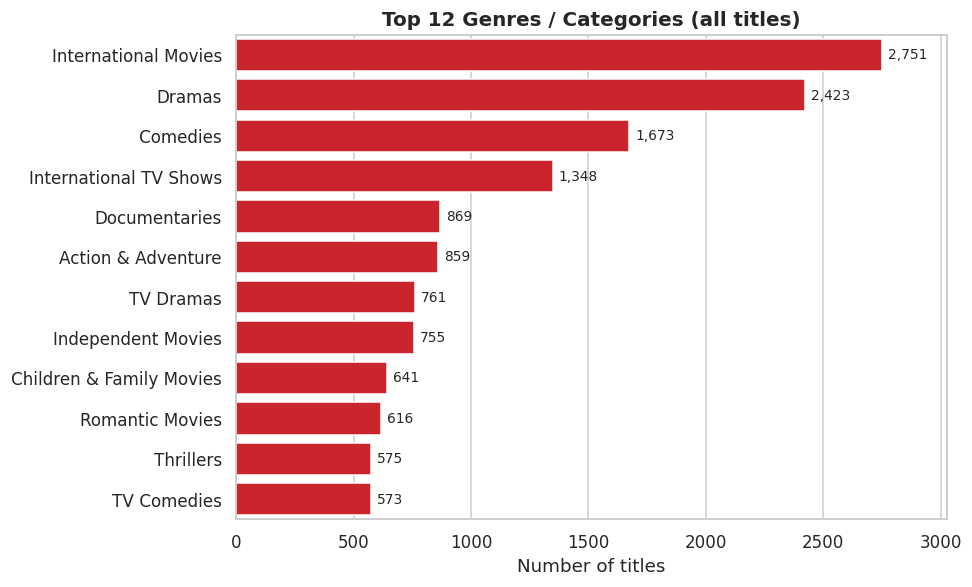

In [13]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(x=top_genres.values, y=top_genres.index, color=NETFLIX_RED, ax=ax)
for i, v in enumerate(top_genres.values):
    ax.text(v + 25, i, f"{v:,}", va="center", fontsize=9)
ax.set_title("Top 12 Genres / Categories (all titles)"); ax.set_xlabel("Number of titles"); ax.set_ylabel("")
ax.set_xlim(0, top_genres.max() * 1.1)
plt.tight_layout(); plt.show()

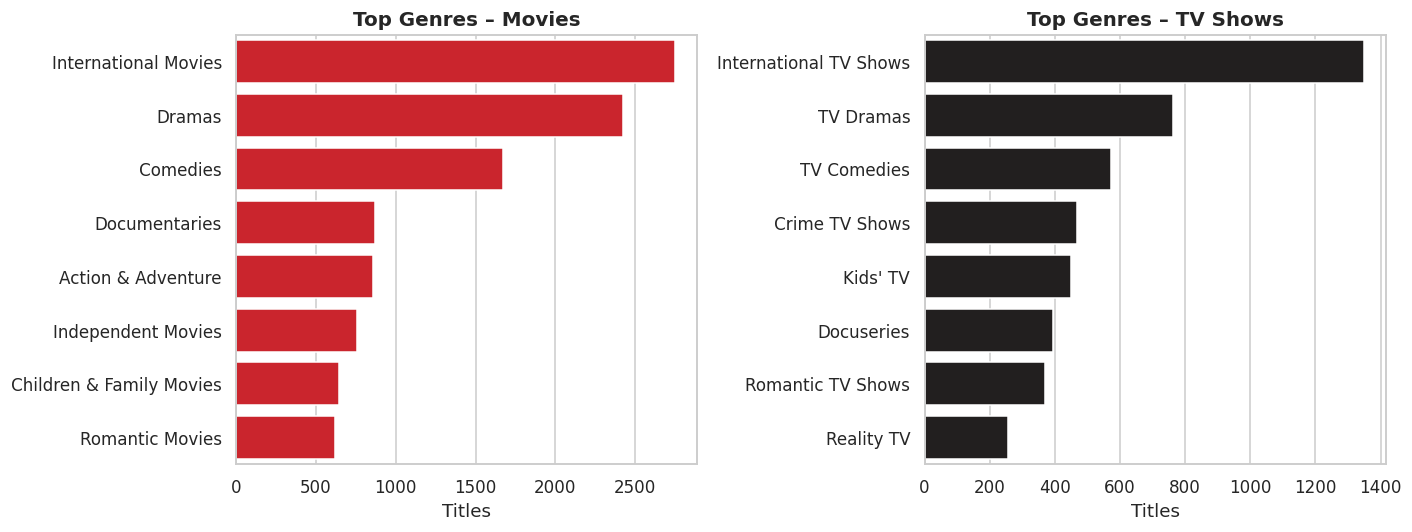

In [14]:
# Top genres separately for movies and TV shows
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, t in zip(axes, ["Movie", "TV Show"]):
    top = genres.loc[genres["type"] == t, "genre"].value_counts().head(8)
    sns.barplot(x=top.values, y=top.index, color=TYPE_COLORS[t], ax=ax)
    ax.set_title(f"Top Genres – {t}s"); ax.set_xlabel("Titles"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

- **International Movies**, **Dramas** and **Comedies** dominate the movie catalogue; International Movies alone tag ~45% of all movies.
- For TV, **International TV Shows**, **TV Dramas** and **TV Comedies** lead, with Crime TV Shows and Kids' TV close behind.
- A title carries about **2.2 genre tags** on average, which is why genre counts add up to more than the number of titles.

## Step 4 – Visualizations for key metrics

### 4.1 Audience ratings

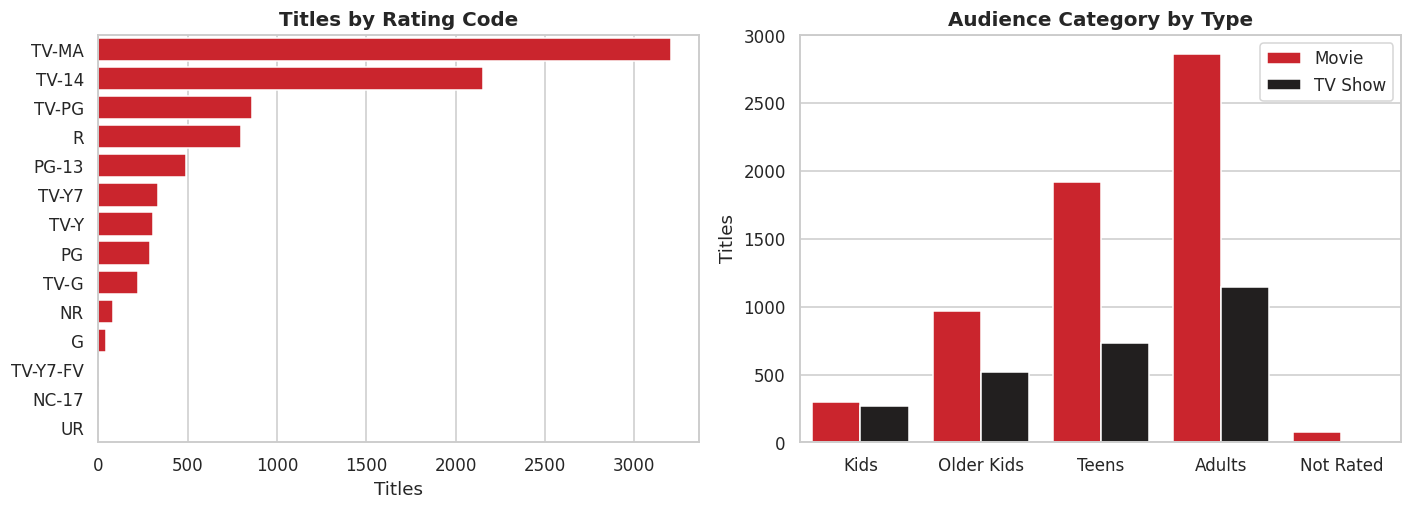

,percent
rating_category,
Kids,6.5
Older Kids,16.9
Teens,30.1
Adults,45.6
Not Rated,0.9


In [15]:
order = ["Kids", "Older Kids", "Teens", "Adults", "Not Rated"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

rating_order = df["rating"].value_counts().index
sns.countplot(data=df, y="rating", order=rating_order, color=NETFLIX_RED, ax=axes[0])
axes[0].set_title("Titles by Rating Code"); axes[0].set_xlabel("Titles"); axes[0].set_ylabel("")

sns.countplot(data=df, x="rating_category", hue="type", order=order, palette=TYPE_COLORS, ax=axes[1])
axes[1].set_title("Audience Category by Type"); axes[1].set_xlabel(""); axes[1].set_ylabel("Titles"); axes[1].legend(title="")
plt.tight_layout(); plt.show()

(df["rating_category"].value_counts(normalize=True).reindex(order) * 100).round(1).to_frame("percent")

**TV-MA** (about 36%) and **TV-14** (about 25%) are the most common codes. Content for **Adults is ~46%** of the catalogue and Teens ~30%, so Netflix leans towards mature audiences; Kids-only content is just ~6.5%.

### 4.2 Movie duration and TV show seasons

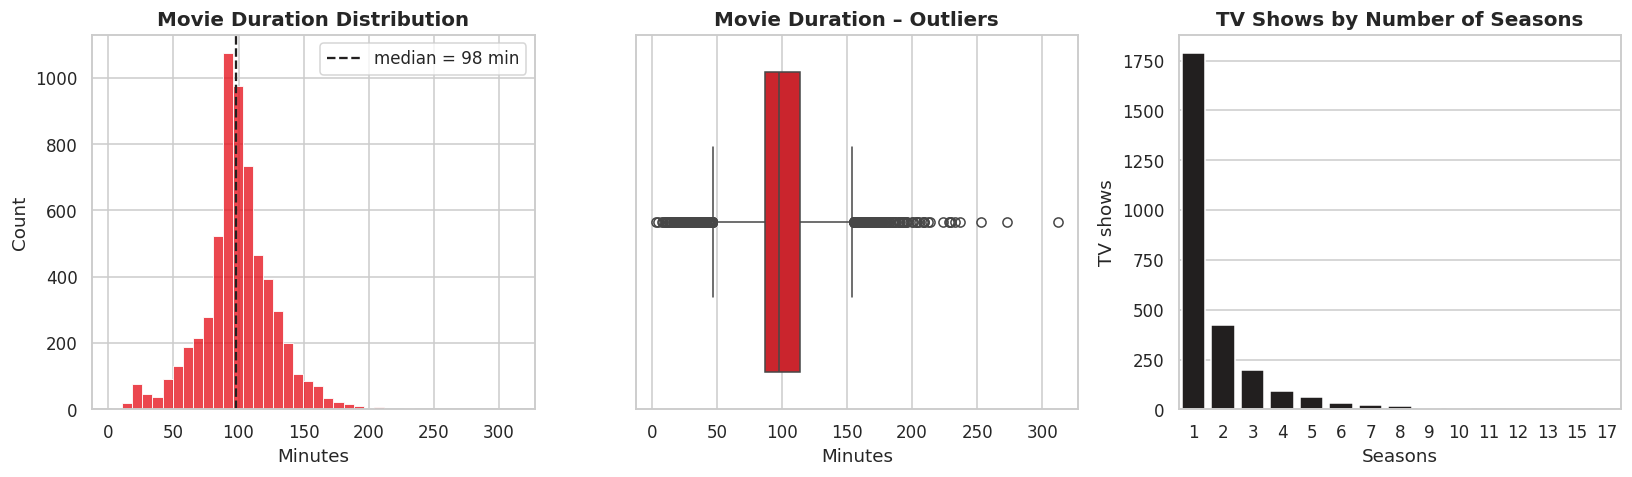

count    6123.0
mean       99.6
std        28.3
min         3.0
25%        87.0
50%        98.0
75%       114.0
max       312.0

TV shows with a single season: 67.2%


In [16]:
movies = df[df["type"] == "Movie"]
shows = df[df["type"] == "TV Show"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.histplot(movies["duration_minutes"], bins=40, color=NETFLIX_RED, ax=axes[0])
axes[0].axvline(movies["duration_minutes"].median(), color=DARK, ls="--", label=f"median = {movies['duration_minutes'].median():.0f} min")
axes[0].set_title("Movie Duration Distribution"); axes[0].set_xlabel("Minutes"); axes[0].legend()

sns.boxplot(x=movies["duration_minutes"], color=NETFLIX_RED, ax=axes[1])
axes[1].set_title("Movie Duration – Outliers"); axes[1].set_xlabel("Minutes")

season_counts = shows["seasons"].astype(int).value_counts().sort_index()
sns.barplot(x=season_counts.index, y=season_counts.values, color=DARK, ax=axes[2])
axes[2].set_title("TV Shows by Number of Seasons"); axes[2].set_xlabel("Seasons"); axes[2].set_ylabel("TV shows")
plt.tight_layout(); plt.show()

print(movies["duration_minutes"].describe().round(1).to_string())
print(f"\nTV shows with a single season: {(shows['seasons'] == 1).mean():.1%}")

- Movie length is roughly bell-shaped: **median 98 min**, most films between **87 and 114 min**. The box plot flags short films (a few minutes) and very long ones (up to 312 min) as outliers.
- **About 67% of TV shows have just one season**; long-running series (5+ seasons) are rare.

### 4.3 Release years

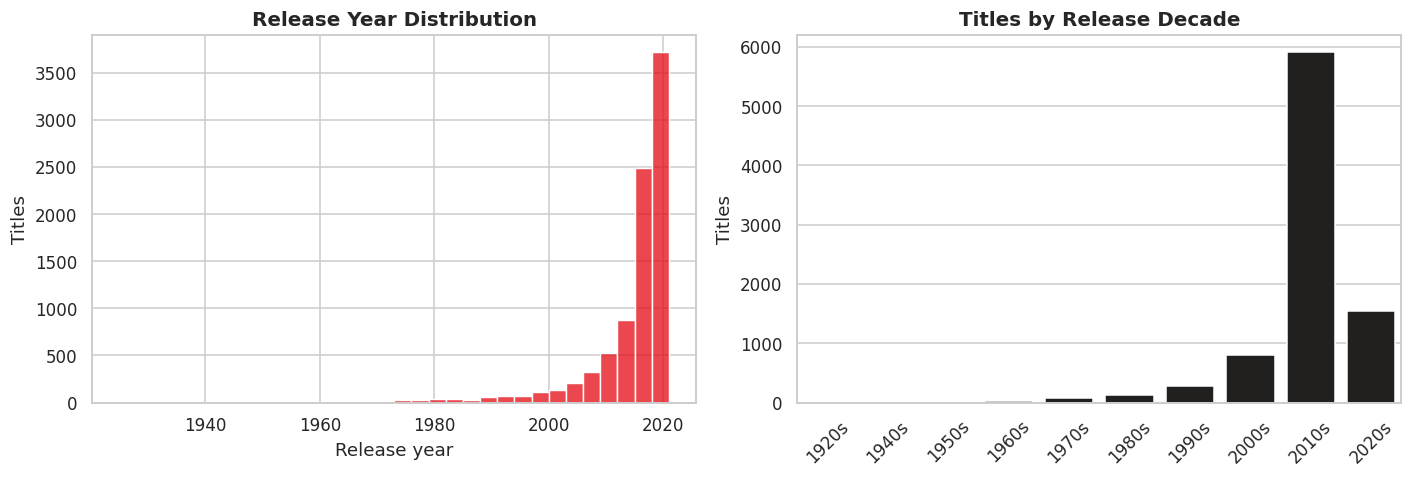

Released 2015 or later: 70.6%


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df["release_year"], bins=range(1925, 2023, 3), color=NETFLIX_RED, ax=axes[0])
axes[0].set_title("Release Year Distribution"); axes[0].set_xlabel("Release year"); axes[0].set_ylabel("Titles")

dec = df["release_decade"].value_counts().sort_index()
sns.barplot(x=dec.index, y=dec.values, color=DARK, ax=axes[1])
axes[1].set_title("Titles by Release Decade"); axes[1].set_xlabel(""); axes[1].set_ylabel("Titles")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

print(f"Released 2015 or later: {(df['release_year'] >= 2015).mean():.1%}")

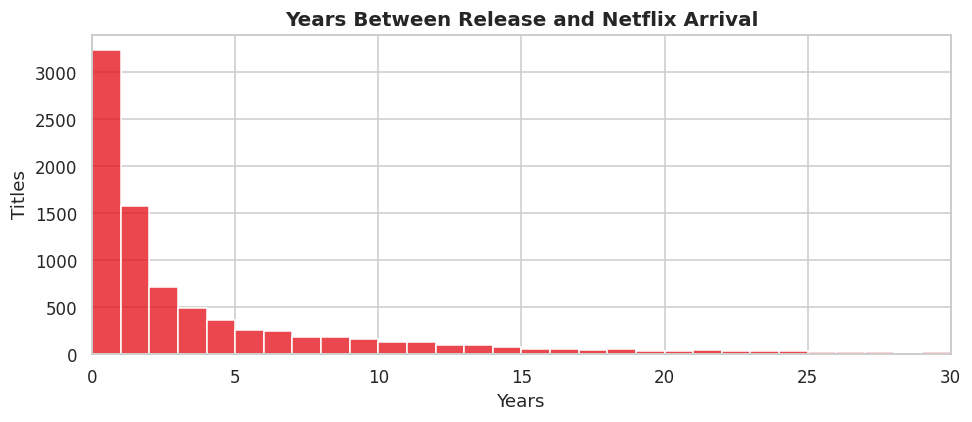

count    8772.0
mean        4.7
std         8.8
min         0.0
25%         0.0
50%         1.0
75%         5.0
max        93.0


In [18]:
# Release gap: how long after release does a title reach Netflix?
gap = df[df["years_to_netflix"] >= 0]
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(gap["years_to_netflix"], bins=range(0, 40), color=NETFLIX_RED, ax=ax)
ax.set_xlim(0, 30); ax.set_title("Years Between Release and Netflix Arrival")
ax.set_xlabel("Years"); ax.set_ylabel("Titles")
plt.tight_layout(); plt.show()
print(gap["years_to_netflix"].describe().round(1).to_string())

About **71% of titles were released in 2015 or later**. Most arrive within a year or two of release, but there is a long tail of older catalogue titles (some 50+ years old).

### 4.4 When is content added? (seasonality)

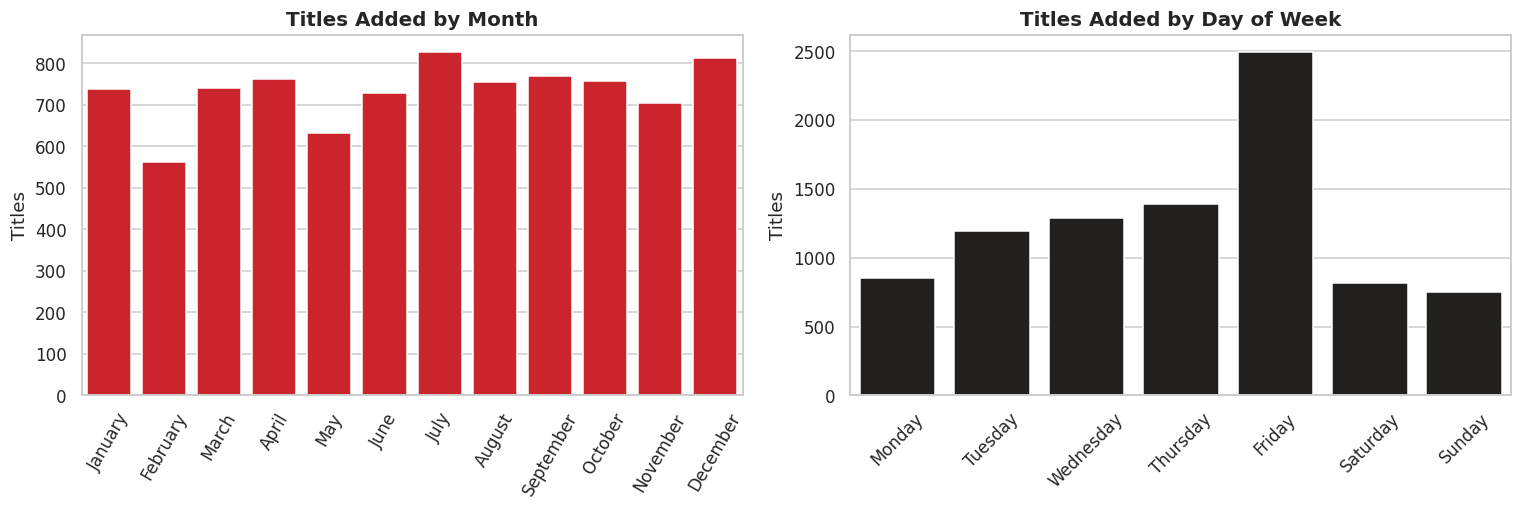

In [19]:
months = ["January","February","March","April","May","June","July","August","September","October","November","December"]
days = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

m = df["month_name"].value_counts().reindex(months)
sns.barplot(x=m.index, y=m.values, color=NETFLIX_RED, ax=axes[0])
axes[0].set_title("Titles Added by Month"); axes[0].set_xlabel(""); axes[0].set_ylabel("Titles")
axes[0].tick_params(axis="x", rotation=60)

d = df["day_of_week"].value_counts().reindex(days)
sns.barplot(x=d.index, y=d.values, color=DARK, ax=axes[1])
axes[1].set_title("Titles Added by Day of Week"); axes[1].set_xlabel(""); axes[1].set_ylabel("Titles")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

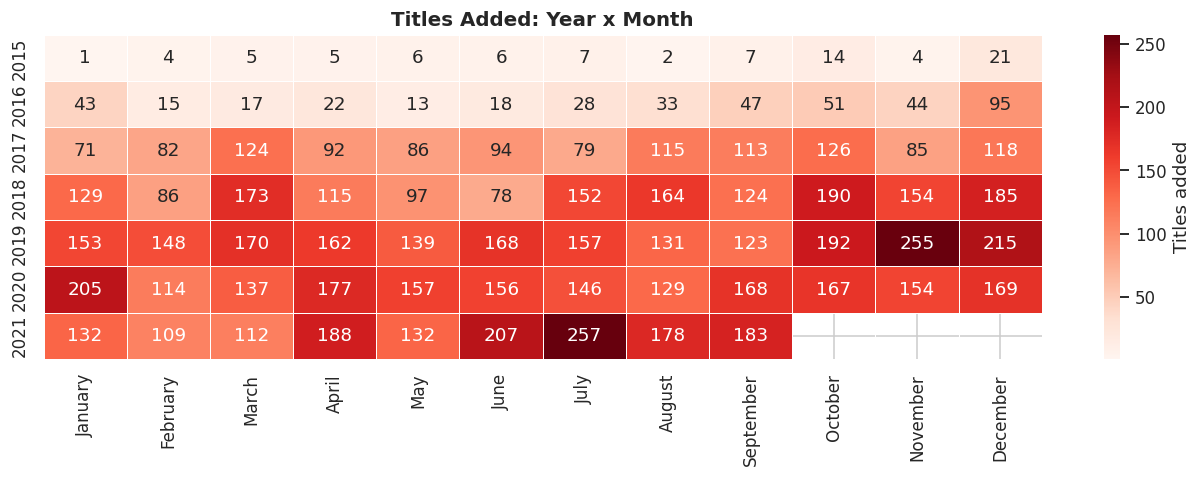

In [20]:
# Year x Month heatmap
heat = (df[df["year_added"] >= 2015].pivot_table(index="year_added", columns="month_name", values="show_id", aggfunc="count")
        .reindex(columns=months))
plt.figure(figsize=(12, 4.5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Reds", linewidths=0.5, cbar_kws={"label": "Titles added"})
plt.title("Titles Added: Year x Month"); plt.xlabel(""); plt.ylabel("")
plt.tight_layout(); plt.show()

- **Friday** is by far the busiest day (~28% of additions), matching Netflix's habit of launching content at the end of the week.
- Months are fairly even, with **July, December, September and April** slightly ahead; the heatmap confirms the 2018–2020 volume boom.

### 4.5 Correlation of numeric features

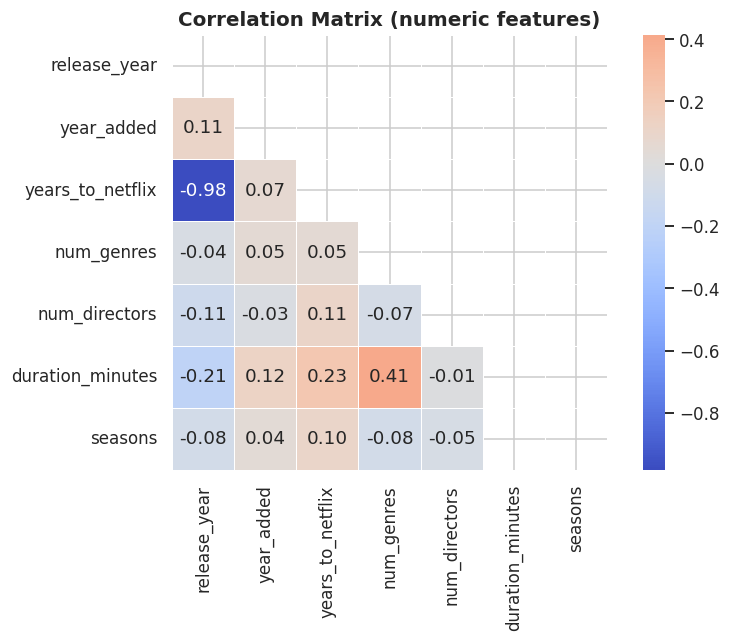

In [21]:
corr_cols = ["release_year", "year_added", "years_to_netflix", "num_genres", "num_directors", "duration_minutes", "seasons"]
corr = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Correlation Matrix (numeric features)")
plt.tight_layout(); plt.show()

The strongest relationship (**-0.98**) is `years_to_netflix` vs `release_year`; it is largely built in, since `years_to_netflix` is calculated from `release_year`, so it only confirms that newer titles arrive sooner. The one other notable link is a moderate positive correlation (**about +0.41**) between `duration_minutes` and `num_genres` (longer movies carry more genre tags). Everything else is weak, so duration, seasons and director count are largely independent of release timing.

### 4.6 Which categories lead for each audience?

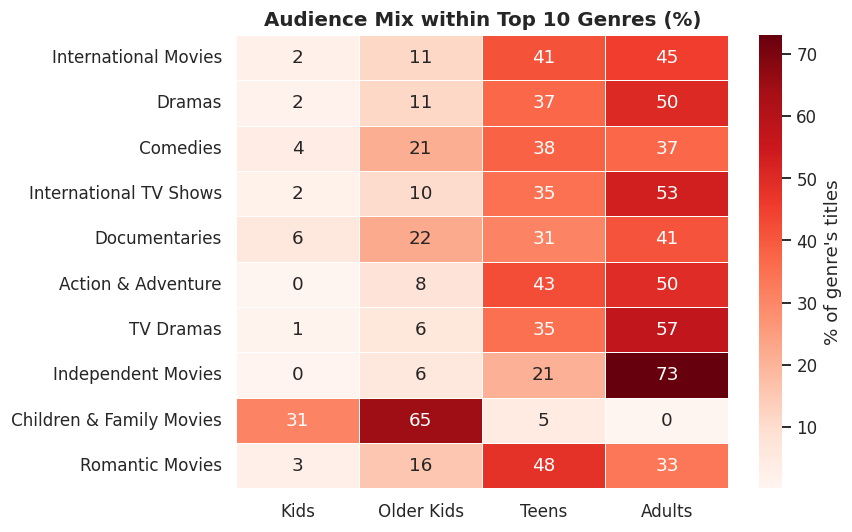

In [22]:
top_g = genres["genre"].value_counts().head(10).index
ct = pd.crosstab(genres["genre"], genres["rating_category"]).loc[top_g, ["Kids", "Older Kids", "Teens", "Adults"]]
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100

plt.figure(figsize=(8, 5))
sns.heatmap(ct_pct, annot=True, fmt=".0f", cmap="Reds", linewidths=0.5, cbar_kws={"label": "% of genre's titles"})
plt.title("Audience Mix within Top 10 Genres (%)"); plt.xlabel(""); plt.ylabel("")
plt.tight_layout(); plt.show()

Most big genres skew to Adults and Teens (e.g. **Independent Movies 73% Adults**, **TV Dramas 57%**, **Dramas 50%**), while **Children & Family Movies are ~96% Kids/Older Kids** – a useful sanity check that the rating grouping from Task 1 behaves sensibly.

### 4.7 Most frequent directors

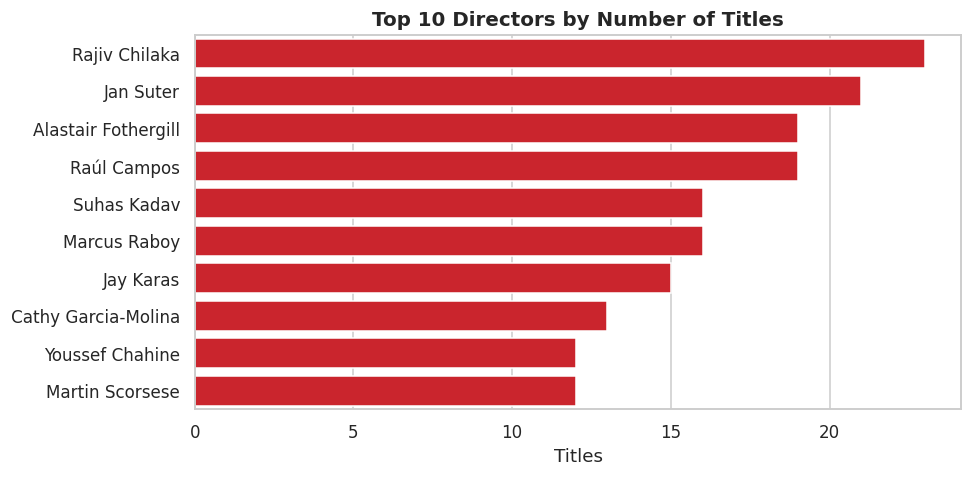

Titles with no director listed: 29.4%  (excluded from this chart)


In [23]:
dirs = (df[df["director"] != "Unknown"]
        .assign(director=lambda d: d["director"].str.split(", ")).explode("director"))
top_dir = dirs["director"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=top_dir.values, y=top_dir.index, color=NETFLIX_RED, ax=ax)
ax.set_title("Top 10 Directors by Number of Titles"); ax.set_xlabel("Titles"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
print(f"Titles with no director listed: {df['director_missing'].mean():.1%}  (excluded from this chart)")

## Step 5 – Summary of findings

In [24]:
summary = pd.DataFrame({
    "Metric": [
        "Total titles", "Movies / TV Shows", "Top country", "Top genre (all titles)", "Most common rating",
        "Median movie length", "TV shows with 1 season", "Peak year for additions", "Busiest day to add content",
        "Titles released 2015 or later",
    ],
    "Value": [
        f"{len(df):,}",
        f"{(df['type']=='Movie').mean():.1%} / {(df['type']=='TV Show').mean():.1%}",
        f"{known['country'].value_counts().index[0]} ({known['country'].value_counts().iloc[0]:,})",
        f"{genres['genre'].value_counts().index[0]} ({genres['genre'].value_counts().iloc[0]:,})",
        f"{df['rating'].value_counts().index[0]} ({df['rating'].value_counts(normalize=True).iloc[0]:.1%})",
        f"{movies['duration_minutes'].median():.0f} min",
        f"{(shows['seasons']==1).mean():.1%}",
        f"{df['year_added'].value_counts().idxmax()} ({df['year_added'].value_counts().max():,} titles)",
        df["day_of_week"].value_counts().idxmax(),
        f"{(df['release_year']>=2015).mean():.1%}",
    ],
})
summary

,Metric,Value
0,Total titles,"8,786"
1,Movies / TV Shows,69.7% / 30.3%
2,Top country,"United States (3,240)"
3,Top genre (all titles),"International Movies (2,751)"
4,Most common rating,TV-MA (36.5%)
5,Median movie length,98 min
6,TV shows with 1 season,67.2%
7,Peak year for additions,"2019 (2,013 titles)"
8,Busiest day to add content,Friday
9,Titles released 2015 or later,70.6%


### Key insights

1. **Movies dominate (~70%)**, though TV shows' share of new additions has recovered from ~25% in 2018 to ~34% in 2021.
2. **Growth peaked in 2019** at roughly 2,000 titles added in a year, then moderated in 2020–2021.
3. **The US leads (~37%)**, followed by India and the UK; together with Pakistan, Canada, Japan and South Korea they account for most of the catalogue. Dozens of other countries contribute small numbers.
4. **Country specialisation:** Pakistan (83%), South Korea (77%) and Japan (66%) lean towards TV shows; India (92%) leans heavily towards movies.
5. **International Movies / Dramas / Comedies** are the biggest categories; International TV Shows, TV Dramas and TV Comedies lead on the TV side.
6. **Mature content prevails:** TV-MA and TV-14 together cover ~60% of titles, and adult-rated content is ~46%.
7. **Typical movie is ~98 minutes**; **two-thirds of TV shows have only one season**, so Netflix carries many short-run or recent series.
8. **Catalogue is recent:** ~71% of titles were released from 2015 onward, and the median title arrives about a year after release.
9. **Friday is the launch day** (~28% of all additions).
10. **Data caveats:** ~29% of titles have no director and ~3% no country (flagged in Task 1), so director and country analyses describe the known records only.


## Thank You 